# AI-Miniproject : ระบบพยากรณ์ยอดขายอาหารสำหรับวันถัดไปด้วย Machine Learning

**แนวคิด:** เรียนรู้จากข้อมูลยอดขายร้านอาหารในอดีต (`restaurant_sales_data.csv`, ปี 2024) เพื่อสร้างโมเดลพยากรณ์ **ยอดขายรวมทั้งหมดของวันถัดไป** จากปัจจัยที่ทราบล่วงหน้า ได้แก่ วันในสัปดาห์ เดือน วันหยุด/วันพิเศษ (จาก `patithinthai_2570.csv`) โปรโมชั่น และสภาพอากาศ

**เป้าหมาย:** ช่วยตอบคำถาม *"พรุ่งนี้ร้านควรเตรียมอาหารประมาณเท่าไหร่ เพื่อให้เพียงพอกับลูกค้าและลดอาหารเหลือทิ้ง?"*

**ชื่อ-นามสกุล:** นพปวีย์ ตรีสินธุสมบัติ **รหัสนักศึกษา:** 6710110205



## ขั้นตอนที่ 1: Import ไลบรารีที่จำเป็น

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
print("Import สำเร็จ")

Import สำเร็จ


## ขั้นตอนที่ 2: โหลดข้อมูล (Data Loading)

ใช้ข้อมูล 2 ไฟล์
- **`restaurant_sales_data.csv`** — ยอดขายรายรายการ (ร้าน/เมนู/วัน) ปี 2024 ใช้เป็นข้อมูลสอนโมเดล
- **`patithinthai_2570.csv`** — ปฏิทินวันหยุด/วันพิเศษของไทย ปี พ.ศ. 2570 (ค.ศ. 2027) ใช้เป็นข้อมูลอ้างอิงวันหยุดสำหรับสร้างฟีเจอร์ และใช้ตอนพยากรณ์วันในอนาคต

In [2]:
sales_path = "restaurant_sales_data.csv"
calendar_path = "patithinthai_2570.csv"

sales = pd.read_csv(sales_path)
calendar = pd.read_csv(calendar_path)

sales["date"] = pd.to_datetime(sales["date"], format="%m/%d/%Y")
calendar["date"] = pd.to_datetime(calendar["date"], format="%m/%d/%Y")

print("sales:", sales.shape)
print("calendar:", calendar.shape)
sales.head()

sales: (10000, 13)
calendar: (95, 4)


,date,restaurant_id,restaurant_type,menu_item_name,meal_type,key_ingredients_tags,typical_ingredient_cost,observed_market_price,actual_selling_price,quantity_sold,has_promotion,special_event,weather_condition
0,2024-01-01,11,Food Stall,Laksa,Lunch,"rice noodles, fish broth, tamarind, shrimp pas...",4.5,10.59,12.48,361,False,False,Sunny
1,2024-01-01,7,Casual Dining,Spaghetti Carbonara,Dinner,"spaghetti, eggs, cheese, beef bacon, black pepper",9.0,26.64,60.46,105,False,False,Sunny
2,2024-01-01,23,Fine Dining,Beef Rendang,Dinner,"beef, coconut milk, galangal, lemongrass, spic...",9.0,49.42,80.15,36,False,False,Rainy
3,2024-01-01,22,Food Stall,Roti Canai,Dinner,"flour, ghee, egg, water, curry",0.8,2.04,2.48,503,False,False,Sunny
4,2024-01-01,32,Fine Dining,Spaghetti Carbonara,Lunch,"spaghetti, eggs, cheese, beef bacon, black pepper",9.0,40.30,55.54,262,False,False,Rainy


## ขั้นตอนที่ 3: สำรวจข้อมูลเบื้องต้น (Data Exploration)

In [3]:
print("ช่วงวันที่ของข้อมูลยอดขาย:", sales['date'].min().date(), "ถึง", sales['date'].max().date())
print("จำนวนวันที่มีข้อมูล:", sales['date'].nunique())
print("จำนวนร้านอาหาร:", sales['restaurant_id'].nunique())
print()
sales.info()

ช่วงวันที่ของข้อมูลยอดขาย: 2024-01-01 ถึง 2025-01-01
จำนวนวันที่มีข้อมูล: 367
จำนวนร้านอาหาร: 50

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   date                     10000 non-null  datetime64[us]
 1   restaurant_id            10000 non-null  int64         
 2   restaurant_type          10000 non-null  str           
 3   menu_item_name           10000 non-null  str           
 4   meal_type                10000 non-null  str           
 5   key_ingredients_tags     10000 non-null  str           
 6   typical_ingredient_cost  10000 non-null  float64       
 7   observed_market_price    10000 non-null  float64       
 8   actual_selling_price     10000 non-null  float64       
 9   quantity_sold            10000 non-null  int64         
 10  has_promotion            10000 non-null  bool          
 11  special

In [4]:
print("ค่าว่าง (missing values):")
print(sales.isna().sum())
print("\nแถวซ้ำ:", sales.duplicated().sum())
print("\nสรุปสถิติ quantity_sold:")
sales['quantity_sold'].describe()

ค่าว่าง (missing values):
date                       0
restaurant_id              0
restaurant_type            0
menu_item_name             0
meal_type                  0
key_ingredients_tags       0
typical_ingredient_cost    0
observed_market_price      0
actual_selling_price       0
quantity_sold              0
has_promotion              0
special_event              0
weather_condition          0
dtype: int64

แถวซ้ำ: 0

สรุปสถิติ quantity_sold:


count    10000.00000
mean       286.00040
std        217.28445
min          0.00000
25%        128.00000
50%        245.00000
75%        392.25000
max       1668.00000
Name: quantity_sold, dtype: float64

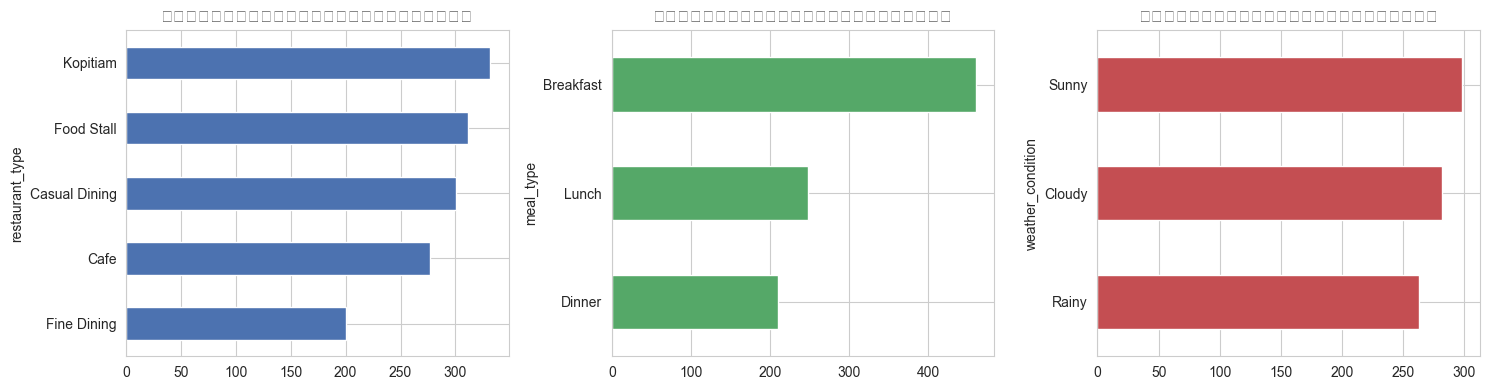

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sales.groupby('restaurant_type')['quantity_sold'].mean().sort_values().plot(kind='barh', ax=axes[0], color="#4C72B0")
axes[0].set_title("ยอดขายเฉลี่ยตามประเภทร้าน")

sales.groupby('meal_type')['quantity_sold'].mean().sort_values().plot(kind='barh', ax=axes[1], color="#55A868")
axes[1].set_title("ยอดขายเฉลี่ยตามมื้ออาหาร")

sales.groupby('weather_condition')['quantity_sold'].mean().sort_values().plot(kind='barh', ax=axes[2], color="#C44E52")
axes[2].set_title("ยอดขายเฉลี่ยตามสภาพอากาศ")
plt.tight_layout(); plt.show()

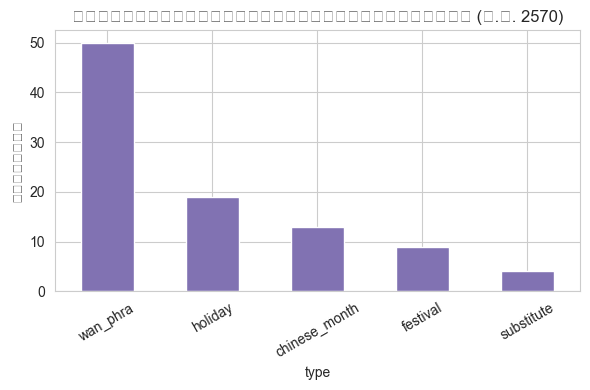

,date,day,be,type
0,2027-01-01,วันศุกร์,2570,holiday
1,2027-01-01,วันศุกร์,2570,wan_phra
2,2027-01-07,วันพฤหัสบดี,2570,wan_phra
3,2027-01-08,วันศุกร์,2570,chinese_month
4,2027-01-15,วันศุกร์,2570,wan_phra


In [6]:
calendar['type'].value_counts().plot(kind='bar', figsize=(6,4), color="#8172B2")
plt.title("จำนวนวันพิเศษแต่ละประเภทในปฏิทิน (พ.ศ. 2570)")
plt.ylabel("จำนวนวัน"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
calendar.head()

## ขั้นตอนที่ 4: ทำความสะอาดและเตรียมปฏิทินวันหยุด (Data Cleaning)

ข้อมูลยอดขายไม่มีค่าว่างหรือแถวซ้ำ จึงไม่ต้องแก้ไขเพิ่มเติม ส่วนปฏิทินวันหยุด (ปี พ.ศ. 2570) จะถูกจับคู่กับข้อมูลยอดขาย (ปี 2024) **โดยใช้ "เดือน-วัน" เป็นตัวจับคู่ (ไม่สนใจปี)** เนื่องจากเรามีปฏิทินวันหยุดแบบละเอียดให้เพียงปีเดียว การจับคู่แบบนี้เป็นการประมาณที่สมเหตุสมผลสำหรับวันหยุดตามปฏิทินสากล (เช่น วันขึ้นปีใหม่ 1 ม.ค.) แต่อาจคลาดเคลื่อนสำหรับวันหยุดที่อิงปฏิทินจันทรคติซึ่งเลื่อนวันไปในแต่ละปี ซึ่งเป็นข้อจำกัดหนึ่งของโครงงานนี้ที่จะกล่าวถึงในรายงาน

In [7]:
calendar['month_day'] = calendar['date'].dt.strftime('%m-%d')

from collections import defaultdict
holiday_types_by_day = defaultdict(set)
for _, row in calendar.iterrows():
    holiday_types_by_day[row['month_day']].add(row['type'])

HOLIDAY_TAGS = ['holiday', 'wan_phra', 'chinese_month', 'festival', 'substitute']

def get_holiday_flags(month_day: str) -> dict:
    """คืนค่า dict ของ flag วันพิเศษ (0/1) สำหรับ 'เดือน-วัน' ที่กำหนด"""
    types_today = holiday_types_by_day.get(month_day, set())
    return {f"is_{t}": int(t in types_today) for t in HOLIDAY_TAGS}

print("ตัวอย่าง: 1 ม.ค. ->", get_holiday_flags("01-01"))
print("ตัวอย่าง: 7 ต.ค.  ->", get_holiday_flags("10-07"))

ตัวอย่าง: 1 ม.ค. -> {'is_holiday': 1, 'is_wan_phra': 1, 'is_chinese_month': 0, 'is_festival': 0, 'is_substitute': 0}
ตัวอย่าง: 7 ต.ค.  -> {'is_holiday': 0, 'is_wan_phra': 0, 'is_chinese_month': 0, 'is_festival': 0, 'is_substitute': 0}


In [8]:
sales['month_day'] = sales['date'].dt.strftime('%m-%d')
flag_df = sales['month_day'].apply(get_holiday_flags).apply(pd.Series)
sales = pd.concat([sales, flag_df], axis=1)
sales[['date'] + [f'is_{t}' for t in HOLIDAY_TAGS]].drop_duplicates('date').iloc[:, 1:].sum()

is_holiday          20
is_wan_phra         51
is_chinese_month    13
is_festival          9
is_substitute        4
dtype: int64

## ขั้นตอนที่ 5: รวมข้อมูลเป็นระดับ "วัน" (Daily Aggregation)

โจทย์ต้องการพยากรณ์ **ยอดขายรวมทั้งร้านในวันถัดไป** ไม่ใช่ยอดขายรายเมนู จึงต้องรวม (`groupby`) ข้อมูลจากระดับรายการ ให้เป็นระดับ 1 แถวต่อ 1 วัน ก่อนนำไปสอนโมเดล

In [9]:
daily = sales.groupby('date').agg(
    total_quantity=('quantity_sold', 'sum'),
    promo_ratio=('has_promotion', 'mean'),      # สัดส่วนรายการที่มีโปรโมชั่นในวันนั้น
    event_ratio=('special_event', 'mean'),      # สัดส่วนรายการที่มี special event ในวันนั้น
    weather_mode=('weather_condition', lambda x: x.mode()[0]),  # สภาพอากาศที่พบบ่อยที่สุดของวันนั้น
    is_holiday=('is_holiday', 'max'),
    is_wan_phra=('is_wan_phra', 'max'),
    is_chinese_month=('is_chinese_month', 'max'),
    is_festival=('is_festival', 'max'),
    is_substitute=('is_substitute', 'max'),
).reset_index()

daily['day_of_week'] = daily['date'].dt.day_name()
daily['month'] = daily['date'].dt.month
daily['is_weekend'] = daily['day_of_week'].isin(['Saturday', 'Sunday']).astype(int)

print("จำนวนวันทั้งหมดหลังรวมข้อมูล:", daily.shape[0])
daily.head()

จำนวนวันทั้งหมดหลังรวมข้อมูล: 367


,date,total_quantity,promo_ratio,event_ratio,weather_mode,is_holiday,is_wan_phra,is_chinese_month,is_festival,is_substitute,day_of_week,month,is_weekend
0,2024-01-01,8479,0.125000,0.041667,Sunny,1,1,0,0,0,Monday,1,0
1,2024-01-02,7647,0.147059,0.029412,Sunny,0,0,0,0,0,Tuesday,1,0
2,2024-01-03,4172,0.210526,0.052632,Sunny,0,0,0,0,0,Wednesday,1,0
3,2024-01-04,7592,0.107143,0.035714,Sunny,0,0,0,0,0,Thursday,1,0
4,2024-01-05,6712,0.071429,0.000000,Sunny,0,0,0,0,0,Friday,1,0


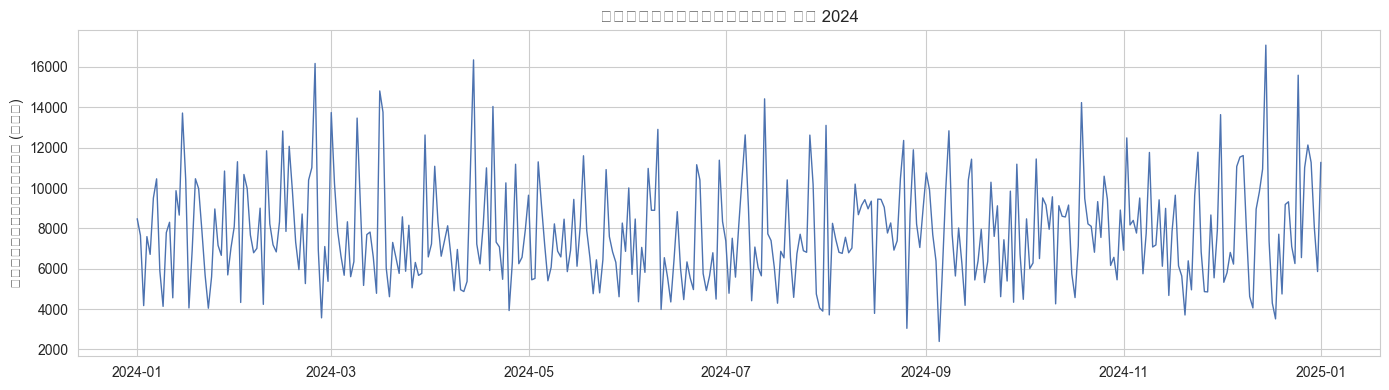

In [10]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily['date'], daily['total_quantity'], color="#4C72B0", linewidth=1)
ax.set_title("ยอดขายรวมรายวัน ปี 2024")
ax.set_ylabel("จำนวนที่ขายได้ (ชุด)")
plt.tight_layout(); plt.show()

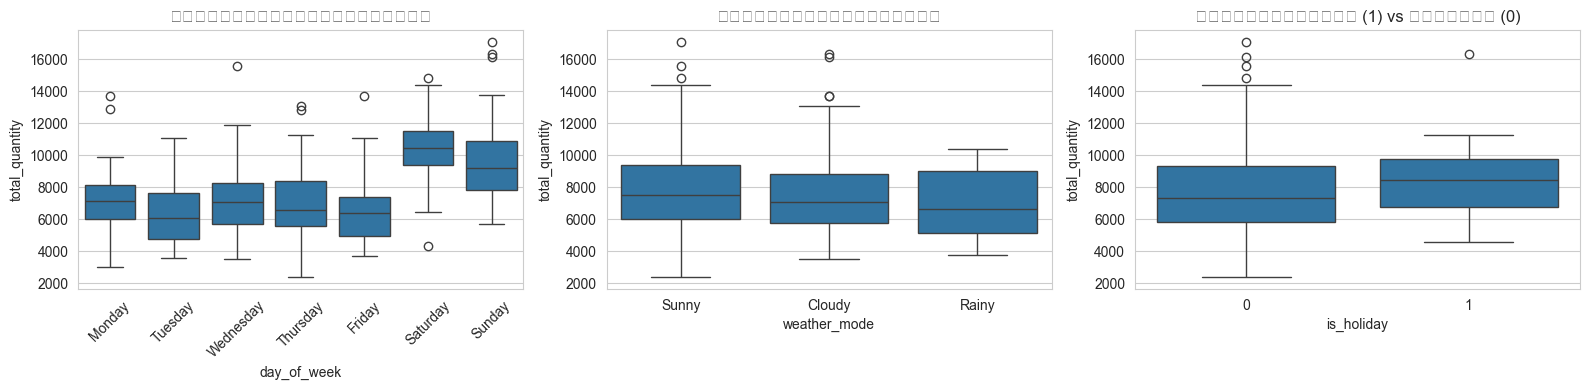

In [11]:
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=daily, x='day_of_week', y='total_quantity', order=order, ax=axes[0])
axes[0].set_title("ยอดขายตามวันในสัปดาห์"); axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=daily, x='weather_mode', y='total_quantity', ax=axes[1])
axes[1].set_title("ยอดขายตามสภาพอากาศ")

sns.boxplot(data=daily, x='is_holiday', y='total_quantity', ax=axes[2])
axes[2].set_title("ยอดขายวันหยุด (1) vs วันปกติ (0)")
plt.tight_layout(); plt.show()

**ข้อสังเกตจากการสำรวจข้อมูล:** ยอดขายวัน **เสาร์-อาทิตย์** สูงกว่าวันธรรมดาอย่างชัดเจน และวันที่มี **โปรโมชั่น** ก็มียอดขายเฉลี่ยสูงกว่าวันที่ไม่มี ส่วนสภาพอากาศมีผลไม่มากนัก ปัจจัยเหล่านี้จึงถูกนำไปใช้เป็นฟีเจอร์ของโมเดล

## ขั้นตอนที่ 6: แยก Features (X) และ Target (y)

- **Target (y):** `total_quantity` — ยอดขายรวมของวันนั้น
- **Features (X):** ปัจจัยที่ **ทราบล่วงหน้าได้** ก่อนถึงวันนั้นจริง (วันในสัปดาห์ เดือน วันหยุด โปรโมชั่นที่วางแผนไว้ สภาพอากาศพยากรณ์) — ไม่ใช้ข้อมูลที่รู้ได้หลังขายจบแล้วเท่านั้น (เช่น จำนวนรายการเมนูที่ขายจริงในวันนั้น) เพื่อป้องกัน Data Leakage

In [12]:
categorical_cols = ['day_of_week', 'weather_mode']
numeric_cols = ['month', 'is_weekend', 'promo_ratio', 'event_ratio',
                'is_holiday', 'is_wan_phra', 'is_chinese_month', 'is_festival', 'is_substitute']
feature_cols = categorical_cols + numeric_cols

X = daily[feature_cols]
y = daily['total_quantity']

print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

X shape: (367, 11) | y shape: (367,)


,day_of_week,weather_mode,month,is_weekend,promo_ratio,event_ratio,is_holiday,is_wan_phra,is_chinese_month,is_festival,is_substitute
0,Monday,Sunny,1,0,0.125000,0.041667,1,1,0,0,0
1,Tuesday,Sunny,1,0,0.147059,0.029412,0,0,0,0,0
2,Wednesday,Sunny,1,0,0.210526,0.052632,0,0,0,0,0
3,Thursday,Sunny,1,0,0.107143,0.035714,0,0,0,0,0
4,Friday,Sunny,1,0,0.071429,0.000000,0,0,0,0,0


## ขั้นตอนที่ 7: แบ่งข้อมูลเป็น Train / Test Set

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")

X_train: (293, 11)  |  X_test: (74, 11)


## ขั้นตอนที่ 8: เตรียม Preprocessing (Feature Encoding)

ตัวแปรเชิงกลุ่ม (`day_of_week`, `weather_mode`) ต้องแปลงเป็นตัวเลขด้วย **One-Hot Encoding** ก่อนป้อนเข้าโมเดล ส่วนตัวแปรตัวเลขอื่น ๆ ใช้ค่าตามเดิม โดยรวมขั้นตอนทั้งหมดไว้ใน `ColumnTransformer` + `Pipeline` เพื่อให้ Preprocessing ถูก fit จาก train set เท่านั้น (ป้องกัน data leakage) และสามารถเรียกใช้ซ้ำกับข้อมูลใหม่ได้ง่าย

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ],
    remainder='passthrough'   # ปล่อยตัวแปรตัวเลขผ่านไปตามเดิม
)

## ขั้นตอนที่ 9: เลือกและสร้างโมเดล Machine Learning (Model Training)

ทดลองเปรียบเทียบโมเดล Regression 4 แบบ ตั้งแต่โมเดลพื้นฐาน (Linear) ไปจนถึงโมเดลที่ซับซ้อนขึ้น (Ensemble/Tree-based) เพื่อดูว่าแบบใดเหมาะกับข้อมูลชุดนี้ที่สุด

In [15]:
candidate_models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=5.0),
    "RandomForest": RandomForestRegressor(n_estimators=400, max_depth=6, min_samples_leaf=4, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=42),
}

trained_pipelines = {}
for name, model in candidate_models.items():
    pipe = Pipeline([('pre', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

print("เทรนโมเดลทั้งหมดเสร็จสิ้น:", list(trained_pipelines.keys()))

เทรนโมเดลทั้งหมดเสร็จสิ้น: ['LinearRegression', 'Ridge', 'RandomForest', 'GradientBoosting']


## ขั้นตอนที่ 10: ประเมินประสิทธิภาพของโมเดล (Model Evaluation)

In [16]:
def evaluate(pipe, X_test, y_test):
    pred = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    r2 = r2_score(y_test, pred)
    mape = float(np.mean(np.abs((y_test - pred) / y_test))) * 100
    return pred, {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE (%)": mape}

eval_rows = []
all_preds = {}
for name, pipe in trained_pipelines.items():
    pred, metrics = evaluate(pipe, X_test, y_test)
    all_preds[name] = pred
    eval_rows.append({"Model": name, **metrics})

results_df = pd.DataFrame(eval_rows).sort_values("R2", ascending=False).reset_index(drop=True)
results_df

,Model,MAE,RMSE,R2,MAPE (%)
0,Ridge,1733.673760,2331.911707,0.318691,25.855820
1,LinearRegression,1761.822365,2357.886449,0.303428,26.008026
2,RandomForest,1847.553969,2462.464369,0.240269,27.568915
3,GradientBoosting,1835.511140,2489.175935,0.223697,27.757418


In [17]:
best_model_name = results_df.iloc[0]['Model']
best_pipeline = trained_pipelines[best_model_name]
print(f"โมเดลที่ดีที่สุด (R2 สูงสุด): {best_model_name}")
results_df.round(2)

โมเดลที่ดีที่สุด (R2 สูงสุด): Ridge


,Model,MAE,RMSE,R2,MAPE (%)
0,Ridge,1733.67,2331.91,0.32,25.86
1,LinearRegression,1761.82,2357.89,0.30,26.01
2,RandomForest,1847.55,2462.46,0.24,27.57
3,GradientBoosting,1835.51,2489.18,0.22,27.76


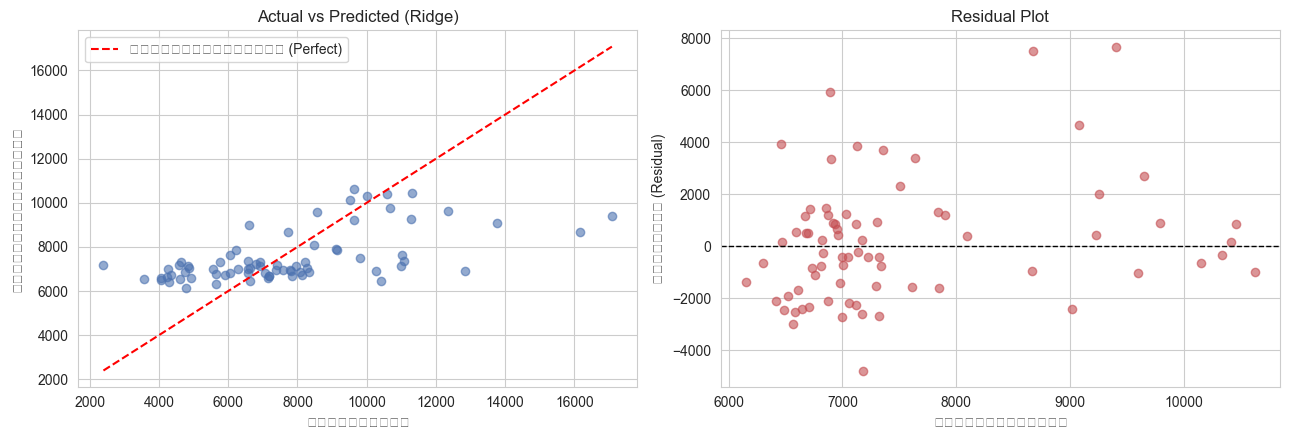

In [18]:
best_pred = all_preds[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(y_test, best_pred, alpha=0.6, color="#4C72B0")
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label="ค่าที่ควรจะเป็น (Perfect)")
axes[0].set_xlabel("ยอดขายจริง"); axes[0].set_ylabel("ยอดขายที่พยากรณ์")
axes[0].set_title(f"Actual vs Predicted ({best_model_name})"); axes[0].legend()

residuals = y_test.values - best_pred
axes[1].scatter(best_pred, residuals, alpha=0.6, color="#C44E52")
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel("ค่าที่พยากรณ์"); axes[1].set_ylabel("ส่วนต่าง (Residual)")
axes[1].set_title("Residual Plot")

plt.tight_layout(); plt.show()

## ขั้นตอนที่ 11: ดูความสำคัญของตัวแปร (Feature Importance)

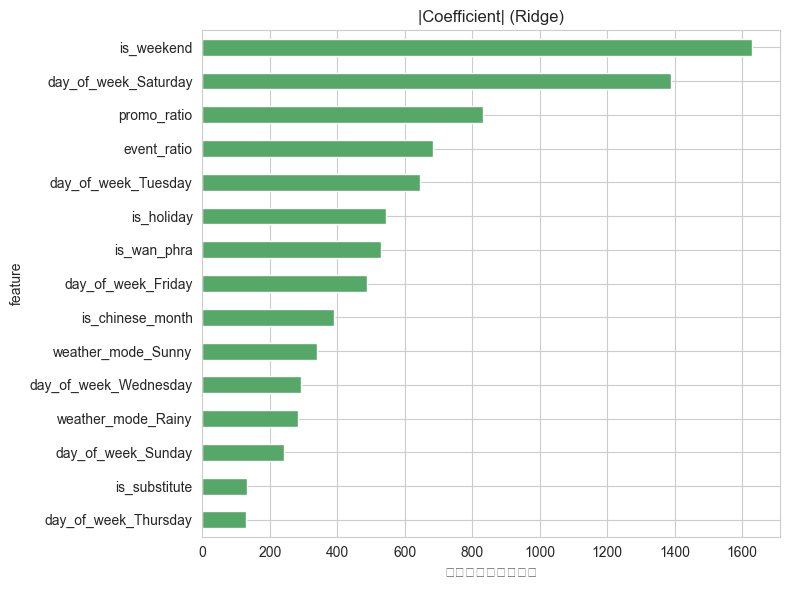

In [19]:
ohe = best_pipeline.named_steps['pre'].named_transformers_['cat']
cat_feature_names = list(ohe.get_feature_names_out(categorical_cols))
all_feature_names = cat_feature_names + numeric_cols

model_obj = best_pipeline.named_steps['model']

if hasattr(model_obj, 'feature_importances_'):
    importances = model_obj.feature_importances_
    title = f"Feature Importance ({best_model_name})"
elif hasattr(model_obj, 'coef_'):
    importances = np.abs(model_obj.coef_)
    title = f"|Coefficient| ({best_model_name})"
else:
    importances = None

if importances is not None:
    imp_df = pd.DataFrame({"feature": all_feature_names, "importance": importances})
    imp_df = imp_df.sort_values("importance", ascending=True).tail(15)
    imp_df.plot(kind='barh', x='feature', y='importance', figsize=(8, 6), legend=False, color="#55A868")
    plt.title(title); plt.xlabel("ความสำคัญ"); plt.tight_layout(); plt.show()

## ขั้นตอนที่ 12: บันทึกโมเดล (Model Saving)

บันทึก Pipeline ที่ดีที่สุด (รวม Preprocessing + Model ไว้ในไฟล์เดียว) ไว้ใช้พยากรณ์ต่อได้โดยไม่ต้องเทรนใหม่

In [20]:
joblib.dump(best_pipeline, "sales_forecast_model.pkl")
joblib.dump(feature_cols, "model_feature_columns.pkl")
print("บันทึกโมเดลเรียบร้อย: sales_forecast_model.pkl")

บันทึกโมเดลเรียบร้อย: sales_forecast_model.pkl


## ขั้นตอนที่ 13: ฟังก์ชันพยากรณ์ยอดขายวันถัดไป (Forecast Function)

ฟังก์ชันนี้รับ **วันที่ที่ต้องการพยากรณ์** พร้อมปัจจัยที่ทราบล่วงหน้า (สภาพอากาศ, มีโปรโมชั่นหรือไม่) แล้ว:
1. คำนวณวันในสัปดาห์ / เดือน / วันหยุดสุดสัปดาห์ จากวันที่
2. ค้นหาข้อมูลวันหยุด/วันพิเศษจากปฏิทิน (`patithinthai_2570.csv`) โดยจับคู่ด้วย "เดือน-วัน"
3. ประกอบเป็นแถวข้อมูล (feature) และพยากรณ์ด้วยโมเดลที่บันทึกไว้
4. แสดงผลลัพธ์ในรูปแบบสรุปที่อ่านง่าย

In [21]:
THAI_DAY_NAME = {
    "Monday": "วันจันทร์", "Tuesday": "วันอังคาร", "Wednesday": "วันพุธ",
    "Thursday": "วันพฤหัสบดี", "Friday": "วันศุกร์", "Saturday": "วันเสาร์", "Sunday": "วันอาทิตย์",
}

def predict_next_day_sales(date_str: str, weather: str = "Sunny", has_promotion: bool = False,
                            model_path: str = "sales_forecast_model.pkl") -> dict:
    """พยากรณ์ยอดขายรวมของวันที่กำหนด

    date_str : รูปแบบ 'DD/MM/YYYY' เช่น '07/10/2026'
    weather  : 'Sunny' | 'Cloudy' | 'Rainy'
    has_promotion : True/False มีโปรโมชั่นในวันนั้นหรือไม่
    """
    pipe = joblib.load(model_path)
    date = pd.to_datetime(date_str, format="%d/%m/%Y")
    month_day = date.strftime("%m-%d")

    holiday_flags = get_holiday_flags(month_day)
    day_of_week_en = date.day_name()
    is_weekend = int(day_of_week_en in ["Saturday", "Sunday"])
    is_special_day = int(is_weekend or holiday_flags["is_holiday"] or holiday_flags["is_festival"])

    row = {
        "day_of_week": day_of_week_en,
        "weather_mode": weather,
        "month": date.month,
        "is_weekend": is_weekend,
        "promo_ratio": 1.0 if has_promotion else 0.0,
        "event_ratio": 1.0 if holiday_flags["is_festival"] else 0.0,
        **holiday_flags,
    }
    X_new = pd.DataFrame([row])[feature_cols]
    predicted_qty = max(0, round(pipe.predict(X_new)[0]))

    print("-" * 40)
    print(f"วันที่พยากรณ์ : {date.strftime('%d/%m/%Y')}")
    print(f"วัน           : {THAI_DAY_NAME[day_of_week_en]}")
    print(f"วันหยุด       : {'Yes' if holiday_flags['is_holiday'] else 'No'}")
    print(f"วันทำงาน      : {'No' if is_weekend or holiday_flags['is_holiday'] else 'Yes'}")
    print(f"Special Event : {'Yes' if is_special_day else 'No'}")
    print(f"สภาพอากาศ     : {weather}")
    print(f"โปรโมชั่น     : {'Yes' if has_promotion else 'No'}")
    print("-" * 40)
    print(f"คาดการณ์ยอดขาย : {predicted_qty:,} ชุด")
    print("-" * 40)
    return {"date": date, "predicted_quantity": predicted_qty, **row}

## ขั้นตอนที่ 14: สาธิตการทำงาน (Demo)

In [22]:
_ = predict_next_day_sales("07/10/2026", weather="Rainy", has_promotion=False)

----------------------------------------
วันที่พยากรณ์ : 07/10/2026
วัน           : วันพุธ
วันหยุด       : No
วันทำงาน      : Yes
Special Event : No
สภาพอากาศ     : Rainy
โปรโมชั่น     : No
----------------------------------------
คาดการณ์ยอดขาย : 6,331 ชุด
----------------------------------------


In [23]:
# ตัวอย่างเพิ่มเติม: วันหยุดสุดสัปดาห์ที่มีโปรโมชั่น เทียบกับวันธรรมดาไม่มีโปรโมชั่น
_ = predict_next_day_sales("09/10/2027", weather="Sunny", has_promotion=True)   # เสาร์, มีโปรโมชั่น
_ = predict_next_day_sales("12/10/2027", weather="Sunny", has_promotion=False)  # วันธรรมดา, ไม่มีโปรโมชั่น

----------------------------------------
วันที่พยากรณ์ : 09/10/2027
วัน           : วันเสาร์
วันหยุด       : No
วันทำงาน      : No
Special Event : Yes
สภาพอากาศ     : Sunny
โปรโมชั่น     : Yes
----------------------------------------
คาดการณ์ยอดขาย : 11,096 ชุด
----------------------------------------
----------------------------------------
วันที่พยากรณ์ : 12/10/2027
วัน           : วันอังคาร
วันหยุด       : No
วันทำงาน      : Yes
Special Event : No
สภาพอากาศ     : Sunny
โปรโมชั่น     : No
----------------------------------------
คาดการณ์ยอดขาย : 6,602 ชุด
----------------------------------------


## ขั้นตอนที่ 16: วิเคราะห์เมนูขายดี (Top Menu Items)

นอกจากพยากรณ์ **ยอดขายรวม** แล้ว ร้านอาหารยังอยากรู้ว่า **ควรเตรียมเมนูไหนมากเป็นพิเศษ** ในวันนั้น ส่วนนี้จะสร้างโปรไฟล์ยอดขายเฉลี่ยของแต่ละเมนู แยกตาม **วันในสัปดาห์** และ **การมีโปรโมชั่น** จากข้อมูลในอดีต เพื่อนำไปประมาณ **สัดส่วน (share)** ของแต่ละเมนูในวันนั้น ๆ แล้วนำไปคูณกับยอดขายรวมที่โมเดลพยากรณ์ได้ จะได้ยอดขายโดยประมาณของแต่ละเมนู และจัดอันดับเมนูขายดี Top 5

In [24]:
sales['day_of_week'] = sales['date'].dt.day_name()

# ยอดขายเฉลี่ยของแต่ละเมนู แยกตาม (วันในสัปดาห์, มีโปรโมชั่นหรือไม่)
menu_profile = sales.groupby(['day_of_week', 'has_promotion', 'menu_item_name'])['quantity_sold'] \
    .mean().reset_index().rename(columns={'quantity_sold': 'avg_qty'})

# สำรองไว้อีกชุดแบบไม่แยกโปรโมชั่น เผื่อข้อมูลย่อยในบางกลุ่มมีน้อยเกินไป
menu_profile_fallback = sales.groupby(['day_of_week', 'menu_item_name'])['quantity_sold'] \
    .mean().reset_index().rename(columns={'quantity_sold': 'avg_qty'})

print("ตัวอย่าง: เมนูขายดีวันเสาร์ที่มีโปรโมชั่น")
menu_profile[(menu_profile['day_of_week'] == 'Saturday') & (menu_profile['has_promotion'] == True)] \
    .sort_values('avg_qty', ascending=False).head(5)

ตัวอย่าง: เมนูขายดีวันเสาร์ที่มีโปรโมชั่น


,day_of_week,has_promotion,menu_item_name,avg_qty
83,Saturday,True,Teh Tarik,1090.120000
76,Saturday,True,Kaya Toast Set,855.333333
80,Saturday,True,Roti Canai,812.611111
75,Saturday,True,Iced Lemon Tea,696.300000
79,Saturday,True,Nasi Lemak,691.666667


In [25]:
def get_menu_ranking(day_of_week_en: str, has_promotion: bool) -> pd.DataFrame:
    """คืนตาราง (เมนู, สัดส่วนยอดขายโดยประมาณ) เรียงจากขายดีไปน้อย สำหรับวัน/เงื่อนไขที่กำหนด"""
    subset = menu_profile[(menu_profile['day_of_week'] == day_of_week_en) &
                           (menu_profile['has_promotion'] == has_promotion)]
    if len(subset) < 5:   # ข้อมูลย่อยน้อยเกินไป -> ใช้ค่าเฉลี่ยแบบไม่แยกโปรโมชั่นแทน
        subset = menu_profile_fallback[menu_profile_fallback['day_of_week'] == day_of_week_en]

    subset = subset.copy()
    subset['share'] = subset['avg_qty'] / subset['avg_qty'].sum()
    return subset[['menu_item_name', 'share']].sort_values('share', ascending=False).reset_index(drop=True)

# ตัวอย่าง
get_menu_ranking('Saturday', True).head(5)

,menu_item_name,share
0,Teh Tarik,0.150096
1,Kaya Toast Set,0.117768
2,Roti Canai,0.111886
3,Iced Lemon Tea,0.095872
4,Nasi Lemak,0.095234


## ขั้นตอนที่ 17: ขยายฟังก์ชันพยากรณ์ ให้แสดง Top 5 เมนูขายดี

ปรับฟังก์ชันพยากรณ์เดิม ให้หลังจากคำนวณ **ยอดขายรวมของวันนั้น** แล้ว นำสัดส่วนเมนู (จากขั้นตอนที่ 16) มาคูณ เพื่อประมาณยอดขายต่อเมนู แล้วแสดง 5 อันดับเมนูขายดีที่คาดว่าจะขายได้มากที่สุด

In [26]:
def predict_next_day_sales(date_str: str, weather: str = "Sunny", has_promotion: bool = False,
                            top_n: int = 5, model_path: str = "sales_forecast_model.pkl") -> dict:
    """พยากรณ์ยอดขายรวมของวันที่กำหนด พร้อมเมนูขายดี Top N

    date_str : รูปแบบ 'DD/MM/YYYY' เช่น '07/10/2026'
    weather  : 'Sunny' | 'Cloudy' | 'Rainy'
    has_promotion : True/False มีโปรโมชั่นในวันนั้นหรือไม่
    """
    pipe = joblib.load(model_path)
    date = pd.to_datetime(date_str, format="%d/%m/%Y")
    month_day = date.strftime("%m-%d")

    holiday_flags = get_holiday_flags(month_day)
    day_of_week_en = date.day_name()
    is_weekend = int(day_of_week_en in ["Saturday", "Sunday"])
    is_special_day = int(is_weekend or holiday_flags["is_holiday"] or holiday_flags["is_festival"])

    row = {
        "day_of_week": day_of_week_en,
        "weather_mode": weather,
        "month": date.month,
        "is_weekend": is_weekend,
        "promo_ratio": 1.0 if has_promotion else 0.0,
        "event_ratio": 1.0 if holiday_flags["is_festival"] else 0.0,
        **holiday_flags,
    }
    X_new = pd.DataFrame([row])[feature_cols]
    predicted_qty = max(0, round(pipe.predict(X_new)[0]))

    # ---- เมนูขายดี Top N ----
    ranking = get_menu_ranking(day_of_week_en, has_promotion).head(top_n).copy()
    ranking['predicted_qty'] = (ranking['share'] * predicted_qty).round().astype(int)

    print("-" * 42)
    print(f"วันที่พยากรณ์ : {date.strftime('%d/%m/%Y')}")
    print(f"วัน           : {THAI_DAY_NAME[day_of_week_en]}")
    print(f"วันหยุด       : {'Yes' if holiday_flags['is_holiday'] else 'No'}")
    print(f"วันทำงาน      : {'No' if is_weekend or holiday_flags['is_holiday'] else 'Yes'}")
    print(f"Special Event : {'Yes' if is_special_day else 'No'}")
    print(f"สภาพอากาศ     : {weather}")
    print(f"โปรโมชั่น     : {'Yes' if has_promotion else 'No'}")
    print("-" * 42)
    print(f"คาดการณ์ยอดขายรวม : {predicted_qty:,} ชุด")
    print("-" * 42)
    print(f"เมนูขายดี Top {top_n} ที่คาดว่าร้านควรเตรียม:")
    for i, r in enumerate(ranking.itertuples(), start=1):
        print(f"  {i}. {r.menu_item_name:<20s} ~ {r.predicted_qty:>5,} ชุด  ({r.share*100:4.1f}% ของยอดขายรวม)")
    print("-" * 42)

    return {"date": date, "predicted_quantity": predicted_qty,
            "top_menu": ranking.to_dict(orient="records"), **row}

## ขั้นตอนที่ 18: สาธิตการทำงานแบบเต็มรูปแบบ (ยอดขายรวม + เมนูขายดี)

In [27]:
_ = predict_next_day_sales("07/10/2026", weather="Rainy", has_promotion=False)

------------------------------------------
วันที่พยากรณ์ : 07/10/2026
วัน           : วันพุธ
วันหยุด       : No
วันทำงาน      : Yes
Special Event : No
สภาพอากาศ     : Rainy
โปรโมชั่น     : No
------------------------------------------
คาดการณ์ยอดขายรวม : 6,331 ชุด
------------------------------------------
เมนูขายดี Top 5 ที่คาดว่าร้านควรเตรียม:
  1. Teh Tarik            ~   991 ชุด  (15.7% ของยอดขายรวม)
  2. Kaya Toast Set       ~   720 ชุด  (11.4% ของยอดขายรวม)
  3. Roti Canai           ~   691 ชุด  (10.9% ของยอดขายรวม)
  4. Iced Lemon Tea       ~   644 ชุด  (10.2% ของยอดขายรวม)
  5. Nasi Lemak           ~   552 ชุด  ( 8.7% ของยอดขายรวม)
------------------------------------------


In [28]:
_ = predict_next_day_sales("09/10/2027", weather="Sunny", has_promotion=True)   # เสาร์ + โปรโมชั่น
_ = predict_next_day_sales("12/10/2027", weather="Sunny", has_promotion=False)  # วันอังคารธรรมดา

------------------------------------------
วันที่พยากรณ์ : 09/10/2027
วัน           : วันเสาร์
วันหยุด       : No
วันทำงาน      : No
Special Event : Yes
สภาพอากาศ     : Sunny
โปรโมชั่น     : Yes
------------------------------------------
คาดการณ์ยอดขายรวม : 11,096 ชุด
------------------------------------------
เมนูขายดี Top 5 ที่คาดว่าร้านควรเตรียม:
  1. Teh Tarik            ~ 1,665 ชุด  (15.0% ของยอดขายรวม)
  2. Kaya Toast Set       ~ 1,307 ชุด  (11.8% ของยอดขายรวม)
  3. Roti Canai           ~ 1,241 ชุด  (11.2% ของยอดขายรวม)
  4. Iced Lemon Tea       ~ 1,064 ชุด  ( 9.6% ของยอดขายรวม)
  5. Nasi Lemak           ~ 1,057 ชุด  ( 9.5% ของยอดขายรวม)
------------------------------------------
------------------------------------------
วันที่พยากรณ์ : 12/10/2027
วัน           : วันอังคาร
วันหยุด       : No
วันทำงาน      : Yes
Special Event : No
สภาพอากาศ     : Sunny
โปรโมชั่น     : No
------------------------------------------
คาดการณ์ยอดขายรวม : 6,602 ชุด
-------------------------------------

------------------------------------------
วันที่พยากรณ์ : 09/10/2027
วัน           : วันเสาร์
วันหยุด       : No
วันทำงาน      : No
Special Event : Yes
สภาพอากาศ     : Sunny
โปรโมชั่น     : Yes
------------------------------------------
คาดการณ์ยอดขายรวม : 11,096 ชุด
------------------------------------------
เมนูขายดี Top 5 ที่คาดว่าร้านควรเตรียม:
  1. Teh Tarik            ~ 1,665 ชุด  (15.0% ของยอดขายรวม)
  2. Kaya Toast Set       ~ 1,307 ชุด  (11.8% ของยอดขายรวม)
  3. Roti Canai           ~ 1,241 ชุด  (11.2% ของยอดขายรวม)
  4. Iced Lemon Tea       ~ 1,064 ชุด  ( 9.6% ของยอดขายรวม)
  5. Nasi Lemak           ~ 1,057 ชุด  ( 9.5% ของยอดขายรวม)
------------------------------------------


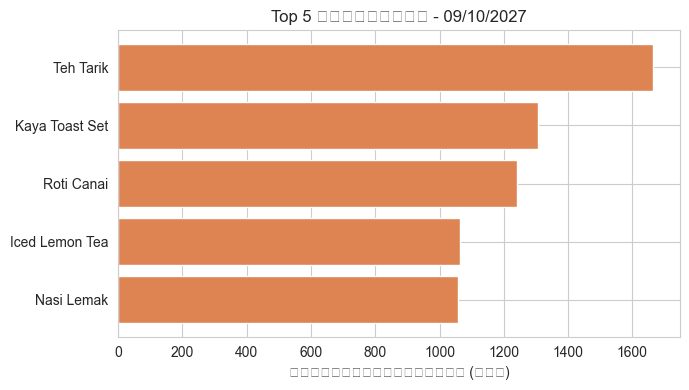

In [29]:
# กราฟแท่งเมนูขายดี Top 5 ของตัวอย่างวันที่ 09/10/2027
result = predict_next_day_sales("09/10/2027", weather="Sunny", has_promotion=True)
top_df = pd.DataFrame(result['top_menu'])

plt.figure(figsize=(7, 4))
plt.barh(top_df['menu_item_name'][::-1], top_df['predicted_qty'][::-1], color="#DD8452")
plt.xlabel("ยอดขายที่คาดการณ์ (ชุด)")
plt.title(f"Top {len(top_df)} เมนูขายดี - {result['date'].strftime('%d/%m/%Y')}")
plt.tight_layout(); plt.show()

## ขั้นตอนที่ 19: UI แบบโต้ตอบอย่างง่าย (ipywidgets) — ใช้ได้เฉพาะใน Jupyter/Colab

เซลล์นี้สร้างแบบฟอร์มให้กรอกวันที่ สภาพอากาศ และโปรโมชั่น แล้วกดปุ่มเพื่อพยากรณ์ยอดขายทันที เหมาะสำหรับใช้ **สาธิต (Demo)** ตอนนำเสนอโครงงาน

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

date_box = widgets.Text(value="07/10/2026", description="วันที่ (DD/MM/YYYY):", style={'description_width': 'initial'})
weather_dd = widgets.Dropdown(options=["Sunny", "Cloudy", "Rainy"], value="Sunny", description="สภาพอากาศ:")
promo_cb = widgets.Checkbox(value=False, description="มีโปรโมชั่น")
btn = widgets.Button(description="พยากรณ์ยอดขาย", button_style="primary")
out = widgets.Output()

def on_click(_):
    with out:
        clear_output()
        try:
            predict_next_day_sales(date_box.value, weather=weather_dd.value, has_promotion=promo_cb.value)
        except Exception as e:
            print("เกิดข้อผิดพลาด:", e)

btn.on_click(on_click)
display(widgets.VBox([date_box, weather_dd, promo_cb, btn, out]))

## สรุป (Summary)

- โมเดลที่ดีที่สุดในการทดลองนี้ ให้ดูจากแถวบนสุดของตาราง `results_df` ในขั้นตอนที่ 10 (เรียงตามค่า R² จากมากไปน้อย) — เมื่อรันครั้งล่าสุดคือ **Ridge Regression**
- ปัจจัยที่มีผลต่อยอดขายมากที่สุดคือ **วันในสัปดาห์ (วันเสาร์-อาทิตย์)** และ **การมีโปรโมชั่น**
- ข้อจำกัด: ข้อมูลยอดขายมีความผันผวนสูงจากปัจจัยที่โมเดลไม่สามารถทราบล่วงหน้าได้ (เช่น จำนวนลูกค้าเฉพาะวัน จำนวนเมนูที่เปิดขายจริง) ทำให้ค่า R² ยังไม่สูงมาก และการจับคู่วันหยุดใช้ "เดือน-วัน" แทนปีจริง ซึ่งอาจคลาดเคลื่อนสำหรับวันหยุดจันทรคติ
- แนวทางพัฒนาต่อ: เพิ่มข้อมูลย้อนหลังหลายปีเพื่อให้โมเดลเห็นฤดูกาล, เพิ่มฟีเจอร์ยอดขายของวันก่อนหน้า (lag features), ลองโมเดล Time Series เฉพาะทาง (เช่น Prophet, ARIMA) และเก็บข้อมูลพยากรณ์อากาศจริงมาทดสอบ